**Cell 1: setup**

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import from src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.load_data import load_raw_data
from src.config import TARGET

df = load_raw_data()
df.shape

(2930, 82)

**Cell 2: target numbers**

In [2]:
y = df[TARGET]
print(y.describe())
print("Skewness:", round(y.skew(), 2))
print("Skewness of log price:", round(np.log1p(y).skew(), 2))
print("90th percentile:", y.quantile(0.90))
print("Houses at or above it:", (y >= y.quantile(0.90)).sum())

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64
Skewness: 1.74
Skewness of log price: -0.01
90th percentile: 281241.69999999995
Houses at or above it: 293


**Cell 3: plots**

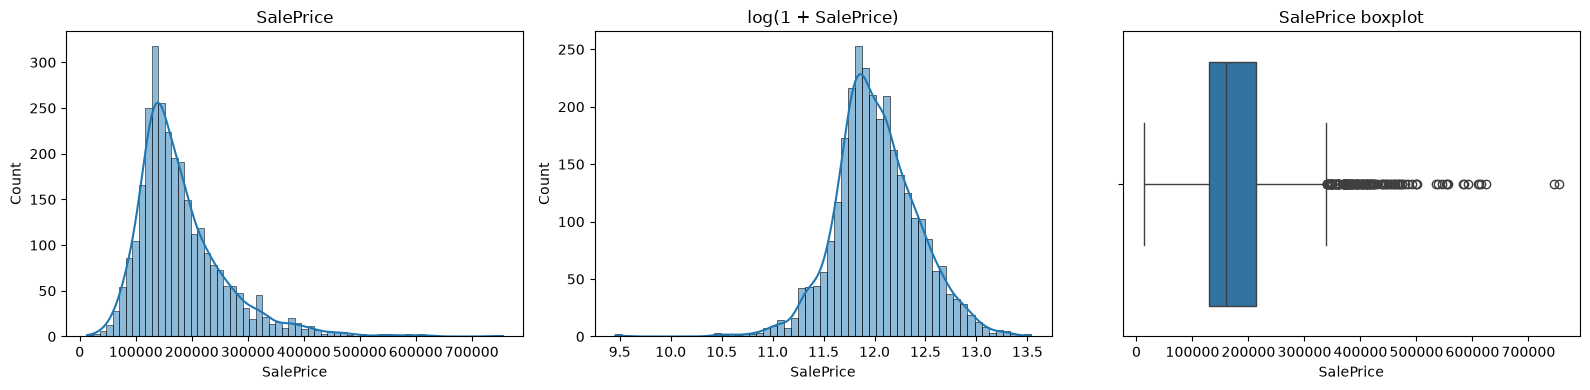

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, kde=True, ax=axes[0]);            axes[0].set_title("SalePrice")
sns.histplot(np.log1p(y), kde=True, ax=axes[1]);  axes[1].set_title("log(1 + SalePrice)")
sns.boxplot(x=y, ax=axes[2]);                     axes[2].set_title("SalePrice boxplot")
plt.tight_layout()
plt.show()

## Findings:
**Graph 1:**
1. Distribution Highly Positively Skewed.
2. Most of the houses prices are concentrated from 1 lakh to 2 lakh
3. Some houses has relatively higher prices which is makeing the right tail long.

**Graph 2:**
1. After log1p Transformation the distribution is more symmetric then before.

**Graph 3:**
1. Distribution has high value observations.
2. House Prices of some observation very high.

**Cell 4: Most Expensive and Most Cheap Houses**

In [4]:
cols = [TARGET, "Gr Liv Area", "Overall Qual", "Neighborhood", "Sale Condition"]
display(df.nlargest(5, TARGET)[cols])
display(df.nsmallest(5, TARGET)[cols])

,SalePrice,Gr Liv Area,Overall Qual,Neighborhood,Sale Condition
1767,755000,4316,10,NoRidge,Normal
1760,745000,4476,10,NoRidge,Abnorml
2445,625000,3627,10,NoRidge,Normal
1063,615000,2470,10,NridgHt,Normal
44,611657,2364,9,NridgHt,Partial


,SalePrice,Gr Liv Area,Overall Qual,Neighborhood,Sale Condition
181,12789,832,2,OldTown,Abnorml
1553,13100,733,1,IDOTRR,Abnorml
726,34900,720,4,IDOTRR,Abnorml
2843,35000,498,2,Edwards,Normal
2880,35311,480,2,IDOTRR,Abnorml


## Findings: Target

1. Effect of Extreme Values

**Finding:** SalePrice is right-skewed (skewness 1.74), and the mean is higher than the median.

**Evidence:** After log(1 + price), skewness drops to -0.01.

**Decision:** We will train on log(1 + SalePrice) and convert predictions back with expm1.

2. Model Performance

**Hypothesis (to test in Phase 7):** Training on log(1 + SalePrice) gives lower percentage error than training on raw SalePrice.

**How we will test it:** Train the same model twice (raw target and log target). Compare both on the original price scale using MdAPE, our main metric from the business document.

**Decision for now:** Use the log target as the default. Change it only if the test shows raw is better.

3. potential high-price outliers.

**Finding:** SalePrice contains several potential high-price outliers.

**Evidence:** values above 339,500, total 137 houses.

**Decision:** we will not directly treat/remove them as outliers because in phase 1 we have decided to do Expensive house analysis.

4. Most Expensive and cheapest houses analaysis

**Finding & Evidence:** House with the highest Gr Liv Area(4476) sold at lower price(745000) then the most expensive house sold(755000) despite its Gr Liv Area(4316) is less then that house, point to be noted: the sales condition of this house is Abnorml. In the Cheapest house list 4 out of 5 are Abnorml.

**Decision:** Prices of the houses with sales condition "Abnorml" can be "noisy", this is an Evidence for our assumption 1 but not a proof be will check it later.
